In [8]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder 
from xgboost import XGBRegressor
from scipy.stats import spearmanr

In [9]:
df = pd.read_csv("data/features.csv")
df.head()

,season,round,circuit_id,driver_id,driver_full_name,team_id,grid_position,finish_position,classified_status,points,...,teammate_losses,teammate_win_pct,pole_q3_time,quali_gap_to_pole,team_avg_pace_delta,rolling_avg_pace_delta,pace_trend,circuit_wet_race_frequency,grid_penalty_places,had_grid_penalty
0,2018,1,Australian Grand Prix,VET,Sebastian Vettel,Ferrari,3.0,1.0,Finished,25.0,...,53.0,0.475248,0 days 00:01:21.164000,0.674,0.6690,0.6690,NaN,0.285714,0,False
1,2018,1,Australian Grand Prix,HAM,Lewis Hamilton,Mercedes,1.0,2.0,Finished,18.0,...,75.0,0.587912,0 days 00:01:21.164000,0.000,0.0000,0.0000,NaN,0.285714,0,False
2,2018,1,Australian Grand Prix,RAI,Kimi Räikkönen,Ferrari,2.0,3.0,Finished,15.0,...,31.0,0.607595,0 days 00:01:21.164000,0.664,0.6690,0.6690,NaN,0.285714,0,False
3,2018,1,Australian Grand Prix,RIC,Daniel Ricciardo,Red Bull Racing,8.0,4.0,Finished,12.0,...,74.0,0.421875,0 days 00:01:21.164000,0.988,0.8515,0.8515,NaN,0.285714,3,True
4,2018,1,Australian Grand Prix,ALO,Fernando Alonso,McLaren,10.0,5.0,Finished,10.0,...,52.0,0.636364,0 days 00:01:21.164000,NaN,NaN,NaN,NaN,0.285714,0,False


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3678 entries, 0 to 3677
Data columns (total 35 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   season                       3678 non-null   int64  
 1   round                        3678 non-null   int64  
 2   circuit_id                   3678 non-null   object 
 3   driver_id                    3678 non-null   object 
 4   driver_full_name             3678 non-null   object 
 5   team_id                      3678 non-null   object 
 6   grid_position                3675 non-null   float64
 7   finish_position              3675 non-null   float64
 8   classified_status            3678 non-null   object 
 9   points                       3678 non-null   float64
 10  q1_time                      3627 non-null   object 
 11  q2_time                      2706 non-null   object 
 12  q3_time                      1785 non-null   object 
 13  race_avg_air_temp 

In [11]:
df.describe()

,season,round,grid_position,finish_position,points,race_avg_air_temp,race_avg_track_temp,delta_i,var_delta_i_norm,avg_team_finish_position,...,avg_finish_grid_delta,teammate_wins,teammate_losses,teammate_win_pct,quali_gap_to_pole,team_avg_pace_delta,rolling_avg_pace_delta,pace_trend,circuit_wet_race_frequency,grid_penalty_places
count,3678.000000,3678.000000,3675.000000,3675.000000,3678.000000,3678.000000,3678.000000,3675.000000,3678.000000,3678.000000,...,3634.000000,3676.000000,3676.000000,3676.000000,1785.000000,2285.000000,2947.000000,1581.000000,3678.000000,3678.000000
mean,2021.906199,11.059815,10.334966,10.546939,5.042278,23.481883,35.455324,0.211973,0.071022,10.548668,...,0.246545,68.706202,62.534548,0.500368,0.841199,0.890595,1.005851,-0.008867,0.246192,0.283306
std,2.471190,6.394025,5.839550,5.801579,7.203144,4.973896,9.125659,5.245468,0.039808,4.890667,...,1.323581,36.925277,27.706561,0.137235,1.134188,1.046978,1.193536,0.500261,0.205190,1.324319
min,2018.000000,1.000000,0.000000,1.000000,0.000000,9.500000,15.205755,-18.000000,0.006316,1.500000,...,-12.000000,1.000000,0.000000,0.138889,0.000000,0.000000,0.000000,-5.008750,0.000000,0.000000
25%,2020.000000,6.000000,5.000000,6.000000,0.000000,20.123188,29.081679,-3.000000,0.039737,6.500000,...,-0.294118,41.000000,42.000000,0.396226,0.292000,0.343000,0.475333,-0.161500,0.125000,0.000000
50%,2022.000000,11.000000,10.000000,11.000000,0.000000,23.477869,35.523529,0.000000,0.063947,11.000000,...,0.400000,68.000000,62.000000,0.475248,0.663000,0.712000,0.836000,-0.010000,0.250000,0.000000
75%,2024.000000,16.000000,15.000000,16.000000,8.000000,27.215584,42.070253,2.000000,0.096316,14.500000,...,1.000000,100.000000,81.000000,0.606557,1.117000,1.156000,1.275000,0.132000,0.333333,0.000000
max,2026.000000,24.000000,22.000000,22.000000,26.000000,36.565854,54.525620,20.000000,0.201342,21.500000,...,12.000000,153.000000,112.000000,1.000000,22.112000,22.112000,22.112000,4.917750,1.000000,18.000000


In [12]:
df.isna().sum()

season                            0
round                             0
circuit_id                        0
driver_id                         0
driver_full_name                  0
team_id                           0
grid_position                     3
finish_position                   3
classified_status                 0
points                            0
q1_time                          51
q2_time                         972
q3_time                        1893
race_avg_air_temp                 0
race_avg_track_temp               0
race_had_rain                     0
delta_i                           3
var_delta_i_norm                  0
avg_team_finish_position          0
rolling_avg_finish_position       0
career_starts_at_circuit          0
avg_finish_at_circuit          1205
finish_grid_delta                 3
avg_finish_grid_delta            44
teammate_wins                     2
teammate_losses                   2
teammate_win_pct                  2
pole_q3_time                

# 1. feature separation

In [13]:
DROP_COLS = [
    "driver_full_name",        # redundant with driver_id
    "classified_status",       # post-race info, leaks target
    "points",                  # post-race info, leaks target
    "q1_time", "q2_time", "q3_time",   # raw timedeltas, replaced by quali_gap_to_pole
    "best_quali_time", "pole_quali_time",  # intermediate columns, not features
    "delta_i",                 # intermediate, replaced by var_delta_i_norm
    "finish_grid_delta",       # per-race, leaks current race info
    "race_had_rain",           # replaced by circuit_wet_race_frequency
]
TARGET = "finish_position"

FEATURE_COLS = [c for c in df.columns if c not in DROP_COLS + [TARGET, "season", "round", "circuit_id", "driver_id"]]

print("Features:", FEATURE_COLS)
print("Count:", len(FEATURE_COLS))

Features: ['team_id', 'grid_position', 'race_avg_air_temp', 'race_avg_track_temp', 'var_delta_i_norm', 'avg_team_finish_position', 'rolling_avg_finish_position', 'career_starts_at_circuit', 'avg_finish_at_circuit', 'avg_finish_grid_delta', 'teammate_wins', 'teammate_losses', 'teammate_win_pct', 'pole_q3_time', 'quali_gap_to_pole', 'team_avg_pace_delta', 'rolling_avg_pace_delta', 'pace_trend', 'circuit_wet_race_frequency', 'grid_penalty_places', 'had_grid_penalty']
Count: 21


# 2. Label Encoding

In [14]:
df.head(1)

,season,round,circuit_id,driver_id,driver_full_name,team_id,grid_position,finish_position,classified_status,points,...,teammate_losses,teammate_win_pct,pole_q3_time,quali_gap_to_pole,team_avg_pace_delta,rolling_avg_pace_delta,pace_trend,circuit_wet_race_frequency,grid_penalty_places,had_grid_penalty
0,2018,1,Australian Grand Prix,VET,Sebastian Vettel,Ferrari,3.0,1.0,Finished,25.0,...,53.0,0.475248,0 days 00:01:21.164000,0.674,0.669,0.669,NaN,0.285714,0,False


In [15]:
# encode team_id
df["team_id_enc"] = df["team_id"].astype("category").cat.codes

# rebuild FEATURE_COLS cleanly — don't try to replace in-place
FEATURE_COLS = [
    c for c in df.columns 
    if c not in DROP_COLS + [TARGET, "season", "round", "circuit_id", "driver_id", "team_id"]
] + ["team_id_enc"]

# deduplicate just in case
FEATURE_COLS = list(dict.fromkeys(FEATURE_COLS))

print("Features:", FEATURE_COLS)
print("Count:", len(FEATURE_COLS))
print("Duplicates:", [x for x in FEATURE_COLS if FEATURE_COLS.count(x) > 1])

Features: ['grid_position', 'race_avg_air_temp', 'race_avg_track_temp', 'var_delta_i_norm', 'avg_team_finish_position', 'rolling_avg_finish_position', 'career_starts_at_circuit', 'avg_finish_at_circuit', 'avg_finish_grid_delta', 'teammate_wins', 'teammate_losses', 'teammate_win_pct', 'pole_q3_time', 'quali_gap_to_pole', 'team_avg_pace_delta', 'rolling_avg_pace_delta', 'pace_trend', 'circuit_wet_race_frequency', 'grid_penalty_places', 'had_grid_penalty', 'team_id_enc']
Count: 21
Duplicates: []


# 3. split dataset

In [16]:
# NEVER random split on time series data
train = df[df["season"] <= 2023]
val   = df[df["season"] == 2024]
test  = df[df["season"] == 2025]   # hold this out, don't touch until final eval

X_train = train[FEATURE_COLS]
y_train = train[TARGET]
X_val   = val[FEATURE_COLS]
y_val   = val[TARGET]

print(f"Train: {len(train)} rows ({train['season'].min()}-{train['season'].max()})")
print(f"Val:   {len(val)} rows")
print(f"Test:  {len(test)} rows (held out)")

Train: 2500 rows (2018-2023)
Val:   479 rows
Test:  479 rows (held out)


# 4. Model definition and training

In [17]:
print(X_train.dtypes.value_counts())
print(X_train.isnull().sum().sort_values(ascending=False).head(10))
print(X_train.shape)

# check for any non-numeric columns sneaking in
non_numeric = X_train.select_dtypes(exclude=[np.number]).columns.tolist()
print("Non-numeric columns:", non_numeric)

float64    16
int64       2
object      1
bool        1
int8        1
Name: count, dtype: int64
pace_trend                1434
quali_gap_to_pole         1283
avg_finish_at_circuit     1023
team_avg_pace_delta        962
rolling_avg_pace_delta     524
avg_finish_grid_delta       37
grid_position                3
teammate_wins                2
teammate_win_pct             2
teammate_losses              2
dtype: int64
(2500, 21)
Non-numeric columns: ['pole_q3_time', 'had_grid_penalty']


# fix bool dtype

In [18]:
# convert bool to int
df["had_grid_penalty"] = df["had_grid_penalty"].astype(int)

# rebuild train/val splits after the conversion
X_train = train[FEATURE_COLS].copy()
X_val   = val[FEATURE_COLS].copy()
X_train["had_grid_penalty"] = X_train["had_grid_penalty"].astype(int)
X_val["had_grid_penalty"]   = X_val["had_grid_penalty"].astype(int)

# verify
print(X_train.dtypes.value_counts())
print("Non-numeric:", X_train.select_dtypes(exclude=[np.number]).columns.tolist())

float64    16
int64       3
object      1
int8        1
Name: count, dtype: int64
Non-numeric: ['pole_q3_time']


In [19]:
# fix nulls in target — DNFs become position 20
y_train = y_train.fillna(20).astype(float)
y_val   = y_val.fillna(20).astype(float)

# confirm
print(f"y_train nulls: {y_train.isna().sum()}")
print(f"y_val nulls:   {y_val.isna().sum()}")
print(f"y_train range: {y_train.min()} - {y_train.max()}")

y_train nulls: 0
y_val nulls:   0
y_train range: 1.0 - 20.0


In [20]:
model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    random_state=42,
)
model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=50,
)

ValueError: DataFrame.dtypes for data must be int, float, bool or category. When categorical type is supplied, the experimental DMatrix parameter`enable_categorical` must be set to `True`.  Invalid columns:pole_q3_time: object

# 5.evaluation

In [14]:
val_preds = model.predict(X_val)

# metric 1: spearman rank correlation per race, averaged
races = val[["season","round"]].drop_duplicates()
spearman_scores = []
top10_hits = []

for _, race in races.iterrows():
    mask = (val["season"] == race["season"]) & (val["round"] == race["round"])
    actual = y_val[mask].values
    pred   = val_preds[mask]

    if len(actual) < 2:
        continue

    corr, _ = spearmanr(actual, pred)
    spearman_scores.append(corr)

    # top-10 hit rate: % of actual top-10 that appear in predicted top-10
    actual_top10 = set(val[mask]["driver_id"].values[np.argsort(actual)[:10]])
    pred_top10   = set(val[mask]["driver_id"].values[np.argsort(pred)[:10]])
    hit_rate = len(actual_top10 & pred_top10) / 10
    top10_hits.append(hit_rate)

print(f"Avg Spearman correlation: {np.mean(spearman_scores):.3f}")
print(f"Avg Top-10 hit rate:      {np.mean(top10_hits):.3f}")
print(f"Median Top-10 hit rate:   {np.median(top10_hits):.3f}")

Avg Spearman correlation: 0.885
Avg Top-10 hit rate:      0.892
Median Top-10 hit rate:   0.900


# 6. feature importance

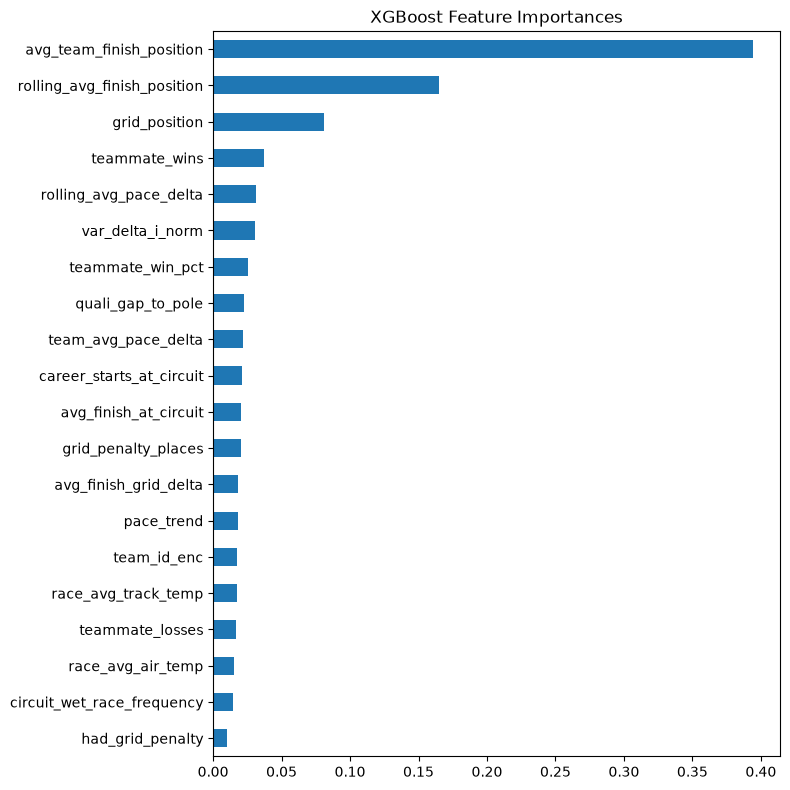

In [15]:
importances = pd.Series(model.feature_importances_, index=FEATURE_COLS)
importances.sort_values().plot(kind="barh", figsize=(8,8))
plt.title("XGBoost Feature Importances")
plt.tight_layout()
plt.show()

# held-out 2025 test set

In [16]:
test = df[df["season"] == 2025]
X_test = test[FEATURE_COLS].copy()
X_test["had_grid_penalty"] = X_test["had_grid_penalty"].astype(int)
y_test = test[TARGET].fillna(20).astype(float).values

test_preds = model.predict(X_test)

races_test = test[["season","round"]].drop_duplicates()
spearman_test, top10_test = [], []

for _, race in races_test.iterrows():
    mask = (test["season"] == race["season"]) & (test["round"] == race["round"])
    actual = y_test[mask.values]
    pred   = test_preds[mask.values]
    if len(actual) < 2:
        continue
    corr, _ = spearmanr(actual, pred)
    spearman_test.append(corr)
    actual_top10 = set(test[mask]["driver_id"].values[np.argsort(actual)[:10]])
    pred_top10   = set(test[mask]["driver_id"].values[np.argsort(pred)[:10]])
    top10_test.append(len(actual_top10 & pred_top10) / 10)

print(f"TEST 2025 Spearman:       {np.mean(spearman_test):.3f}")
print(f"TEST 2025 Top-10 hit:     {np.mean(top10_test):.3f}")

TEST 2025 Spearman:       0.857
TEST 2025 Top-10 hit:     0.871


# save model


In [17]:
import joblib
joblib.dump(model, "models/xgb_race_predictor.pkl")
print("Model saved.")

Model saved.


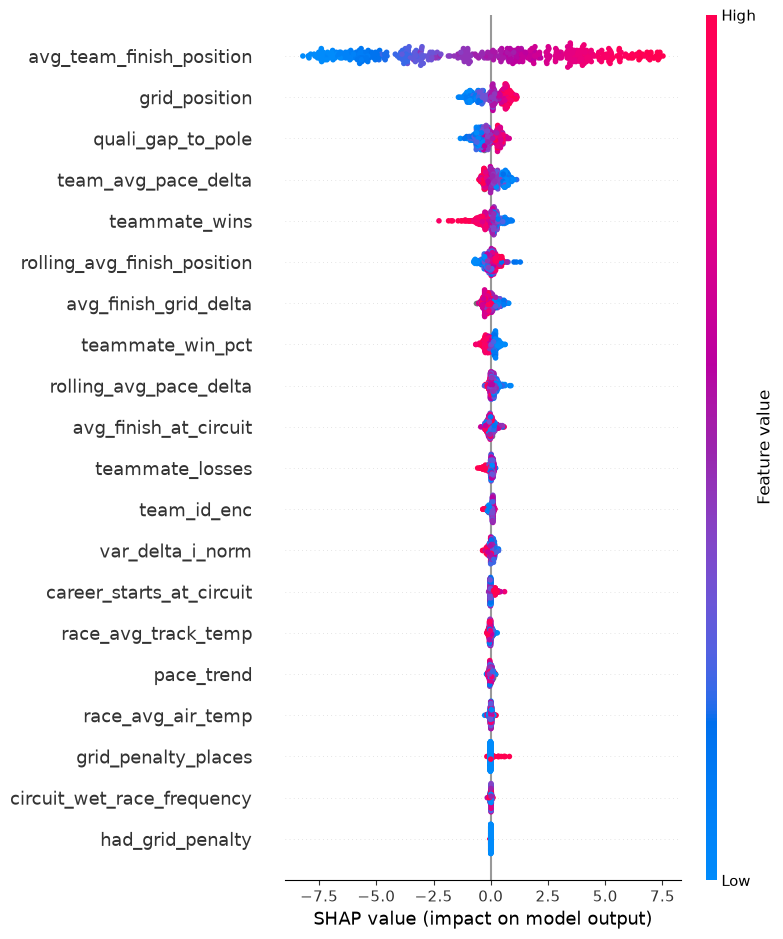

In [18]:
import shap
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_val)
shap.summary_plot(shap_values, X_val, feature_names=FEATURE_COLS)

# LGBMRegressor

In [23]:
from lightgbm import LGBMRegressor
lgbm = LGBMRegressor(n_estimators=300, max_depth=4, learning_rate=0.05)
lgbm.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000373 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2050
[LightGBM] [Info] Number of data points in the train set: 2500, number of used features: 20
[LightGBM] [Info] Start training from score 10.500000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

,max_depth,4
,learning_rate,0.05
,n_estimators,300
,boosting_type,'gbdt'
,num_leaves,31
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


# hyperparam tuning

In [20]:
# Hyperparameter tuning for the XGBoost model
# Run this after the training/preprocessing cells above.

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
from scipy.stats import spearmanr
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

param_grid = {
    "max_depth": [3, 4, 5],
    "learning_rate": [0.05, 0.1, 0.15],
    "n_estimators": [200, 400, 500],
    "min_child_weight": [1, 3, 5],
}

ts_cv = TimeSeriesSplit(n_splits=3)

xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=ts_cv,
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print("Best params:", grid_search.best_params_)
print("Best CV score:", grid_search.best_score_)

# Retrain on train + validation using the best parameters
X_trainval = pd.concat([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])

final_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **grid_search.best_params_,
)
final_model.fit(X_trainval, y_trainval)

# Evaluate on the held-out test set
test_preds = final_model.predict(X_test)

spearman_final, top10_final = [], []
races_test = test[["season", "round"]].drop_duplicates()

for _, race in races_test.iterrows():
    mask = (test["season"] == race["season"]) & (test["round"] == race["round"])
    actual = y_test[mask.values]
    pred = test_preds[mask.values]
    if len(actual) < 2:
        continue
    corr, _ = spearmanr(actual, pred)
    spearman_final.append(corr)
    actual_top10 = set(test.loc[mask, "driver_id"].values[np.argsort(actual)[:10]])
    pred_top10 = set(test.loc[mask, "driver_id"].values[np.argsort(pred)[:10]])
    top10_final.append(len(actual_top10 & pred_top10) / 10)

print(f"FINAL TEST Spearman: {np.mean(spearman_final):.3f}")
print(f"FINAL TEST Top-10 hit: {np.mean(top10_final):.3f}")

Path("models").mkdir(exist_ok=True)
joblib.dump(final_model, "models/xgb_race_predictor_grid_search.pkl")
print("Saved final model to models/xgb_race_predictor_grid_search.pkl")

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best params: {'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 200}
Best CV score: -9.822930034872101
FINAL TEST Spearman: 0.865
FINAL TEST Top-10 hit: 0.863
Saved final model to models/xgb_race_predictor_grid_search.pkl


In [21]:
# Train the model with the best grid-search parameters
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform
from xgboost import XGBRegressor
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

best_params = grid_search.best_params_
print("Using grid-search best params:", best_params)

# Train on train + validation set using the selected parameters
X_trainval = pd.concat([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])

final_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **best_params,
)
final_model.fit(X_trainval, y_trainval)

# Evaluate on the held-out test set
test_preds = final_model.predict(X_test)

spearman_final, top10_final = [], []
races_test = test[["season", "round"]].drop_duplicates()

for _, race in races_test.iterrows():
    mask = (test["season"] == race["season"]) & (test["round"] == race["round"])
    actual = y_test[mask.values]
    pred = test_preds[mask.values]
    if len(actual) < 2:
        continue
    corr, _ = spearmanr(actual, pred)
    spearman_final.append(corr)
    actual_top10 = set(test.loc[mask, "driver_id"].values[np.argsort(actual)[:10]])
    pred_top10 = set(test.loc[mask, "driver_id"].values[np.argsort(pred)[:10]])
    top10_final.append(len(actual_top10 & pred_top10) / 10)

print(f"FINAL TEST Spearman: {np.mean(spearman_final):.3f}")
print(f"FINAL TEST Top-10 hit: {np.mean(top10_final):.3f}")

# Randomized search below grid search for a broader hyperparameter sweep
random_param_grid = {
    "max_depth": [3, 4, 5, 6],
    "learning_rate": uniform(0.01, 0.1),
    "n_estimators": [100, 200, 300, 400, 500],
    "min_child_weight": [1, 3, 5],
}

random_search = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
    ),
    param_distributions=random_param_grid,
    n_iter=12,
    scoring="neg_mean_squared_error",
    cv=ts_cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

random_search.fit(X_train, y_train)

print("Best random-search params:", random_search.best_params_)
print("Best random-search CV score:", random_search.best_score_)

# Train a final model with the random-search best params
random_best_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **random_search.best_params_,
)
random_best_model.fit(X_trainval, y_trainval)

Path("models").mkdir(exist_ok=True)
joblib.dump(random_best_model, "models/xgb_race_predictor_random_search.pkl")
print("Saved random-search model to models/xgb_race_predictor_random_search.pkl")

Using grid-search best params: {'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 200}
FINAL TEST Spearman: 0.865
FINAL TEST Top-10 hit: 0.863
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best random-search params: {'learning_rate': np.float64(0.07116531604882809), 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 100}
Best random-search CV score: -9.804846142717727
Saved random-search model to models/xgb_race_predictor_random_search.pkl


# random forest

In [24]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_val)

# same evaluation loop
spearman_rf, top10_rf = [], []
for _, race in races.iterrows():
    mask = (val["season"] == race["season"]) & (val["round"] == race["round"])
    actual = y_val[mask.values]
    pred   = rf_preds[mask.values]
    if len(actual) < 2:
        continue
    corr, _ = spearmanr(actual, pred)
    spearman_rf.append(corr)
    actual_top10 = set(val[mask]["driver_id"].values[np.argsort(actual)[:10]])
    pred_top10   = set(val[mask]["driver_id"].values[np.argsort(pred)[:10]])
    top10_rf.append(len(actual_top10 & pred_top10) / 10)

print(f"Random Forest Spearman:   {np.mean(spearman_rf):.3f}")
print(f"Random Forest Top-10 hit: {np.mean(top10_rf):.3f}")

Random Forest Spearman:   0.885
Random Forest Top-10 hit: 0.892


In [ ]:
# Compare validation and test metrics across all models

def evaluate_by_race(actual, pred, group_df):
    spearman_scores = []
    top10_hits = []
    mae_scores = []

    for _, race in group_df[["season", "round"]].drop_duplicates().iterrows():
        mask = (group_df["season"] == race["season"]) & (group_df["round"] == race["round"])
        race_actual = actual[mask.values]
        race_pred = pred[mask.values]

        if len(race_actual) < 2:
            continue

        corr, _ = spearmanr(race_actual, race_pred)
        spearman_scores.append(corr)

        actual_top10 = set(group_df.loc[mask, "driver_id"].values[np.argsort(race_actual)[:10]])
        pred_top10 = set(group_df.loc[mask, "driver_id"].values[np.argsort(race_pred)[:10]])
        top10_hits.append(len(actual_top10 & pred_top10) / 10)
        mae_scores.append(np.mean(np.abs(race_actual - race_pred)))

    return {
        "spearman_mean": np.mean(spearman_scores),
        "top10_mean": np.mean(top10_hits),
        "mae_mean": np.mean(mae_scores),
    }

models_to_compare = {
    "Custom XGB": model,
    "Grid Search XGB": final_model,
    "Random Search XGB": random_best_model,
    "LGBMRegressor": lgbm,
    "Random Forest": rf,
}

results = {}
for model_name, model_obj in models_to_compare.items():
    val_pred = model_obj.predict(X_val)
    test_pred = model_obj.predict(X_test)

    val_metrics = evaluate_by_race(y_val, val_pred, val)
    test_metrics = evaluate_by_race(y_test, test_pred, test)

    results[model_name] = {
        "val_spearman": val_metrics["spearman_mean"],
        "val_top10_hit": val_metrics["top10_mean"],
        "val_mae": val_metrics["mae_mean"],
        "test_spearman": test_metrics["spearman_mean"],
        "test_top10_hit": test_metrics["top10_mean"],
        "test_mae": test_metrics["mae_mean"],
    }

comparison_df = pd.DataFrame(results).T
comparison_df.index.name = "Model"
comparison_df.columns.name = "Metric"
comparison_df = comparison_df[[
    "val_spearman",
    "val_top10_hit",
    "val_mae",
    "test_spearman",
    "test_top10_hit",
    "test_mae",
]]

comparison_df.round(3)

## New section: rolling backtest + final retraining

This block is intentionally separate from the older cells. It uses a cleaner, time-aware evaluation strategy with expanding historical windows and trains a final model on all available completed seasons up to the latest data in your feature file.

In [7]:
# Better-version training + Hungarian GP prediction
# This cell is self-contained and does not modify the earlier code.

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr
from xgboost import XGBRegressor
import joblib

# -----------------------------
# 1) Load feature data
# -----------------------------
raw = pd.read_csv("data/features.csv")
raw["had_grid_penalty"] = raw["had_grid_penalty"].astype(int)
raw["team_id_enc"] = raw["team_id"].astype("category").cat.codes

# -----------------------------
# 2) Define feature columns
# -----------------------------
DROP_COLS = [
    "driver_full_name",
    "classified_status",
    "points",
    "q1_time", "q2_time", "q3_time",
    "best_quali_time", "pole_quali_time",
    "delta_i",
    "finish_grid_delta",
    "race_had_rain",
]
TARGET = "finish_position"

FEATURE_COLS = [
    c for c in raw.columns
    if c not in DROP_COLS + [TARGET, "season", "round", "circuit_id", "driver_id", "team_id"]
] + ["team_id_enc"]
FEATURE_COLS = list(dict.fromkeys(FEATURE_COLS))

# Fill target nulls (DNFs become position 20)
raw[TARGET] = raw[TARGET].fillna(20).astype(float)

# -----------------------------
# 3) Rolling backtest evaluation
# -----------------------------
seasons = sorted(raw["season"].unique())
print("Available seasons:", seasons)

val_season = seasons[-2]
test_season = seasons[-1]

print(f"Validation season: {val_season}")
print(f"Test season: {test_season}")

results = []

for holdout_season in [val_season, test_season]:
    train_df = raw[raw["season"] < holdout_season].copy()
    eval_df = raw[raw["season"] == holdout_season].copy()

    X_train = train_df[FEATURE_COLS]
    y_train = train_df[TARGET]
    X_eval = eval_df[FEATURE_COLS]
    y_eval = eval_df[TARGET]

    model = XGBRegressor(
        objective="reg:squarederror",
        n_estimators=400,
        max_depth=4,
        learning_rate=0.08,
        subsample=0.9,
        colsample_bytree=0.9,
        min_child_weight=3,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
    )

    model.fit(X_train, y_train)
    preds = model.predict(X_eval)

    race_metrics = []
    for _, race in eval_df[["season", "round"]].drop_duplicates().iterrows():
        mask = (eval_df["season"] == race["season"]) & (eval_df["round"] == race["round"])
        actual = y_eval[mask].to_numpy()
        pred = preds[mask]

        if len(actual) < 2:
            continue

        corr, _ = spearmanr(actual, pred)
        top10_actual = set(eval_df.loc[mask, "driver_id"].to_numpy()[np.argsort(actual)[:10]])
        top10_pred = set(eval_df.loc[mask, "driver_id"].to_numpy()[np.argsort(pred)[:10]])
        hit_rate = len(top10_actual & top10_pred) / 10
        mae = mean_absolute_error(actual, pred)

        race_metrics.append({
            "spearman": corr,
            "top10_hit": hit_rate,
            "mae": mae,
        })

    results.append({
        "holdout_season": holdout_season,
        "mean_spearman": np.mean([m["spearman"] for m in race_metrics]),
        "mean_top10_hit": np.mean([m["top10_hit"] for m in race_metrics]),
        "mean_mae": np.mean([m["mae"] for m in race_metrics]),
    })

print(pd.DataFrame(results))

# -----------------------------
# 4) Train final model on all completed data
# -----------------------------
final_train_df = raw[raw["season"] < max(raw["season"])].copy()
final_eval_df = raw[raw["season"] == max(raw["season"])].copy()

X_final_train = final_train_df[FEATURE_COLS]
y_final_train = final_train_df[TARGET]
X_final_eval = final_eval_df[FEATURE_COLS]
y_final_eval = final_eval_df[TARGET]

final_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=400,
    max_depth=4,
    learning_rate=0.08,
    subsample=0.9,
    colsample_bytree=0.9,
    min_child_weight=3,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
)

final_model.fit(X_final_train, y_final_train)
final_preds = final_model.predict(X_final_eval)

print("Final model trained on all completed seasons up to", max(raw["season"]) - 1)
print("Latest-season evaluation MAE:", mean_absolute_error(y_final_eval.to_numpy(), final_preds))

Path("models").mkdir(exist_ok=True)
joblib.dump(final_model, "models/xgb_race_predictor_rolling_retrain.pkl")
print("Saved final rolling model to models/xgb_race_predictor_rolling_retrain.pkl")

# -----------------------------
# 5) Predict Hungarian Grand Prix
# -----------------------------
df_pred = raw.copy()
df_pred["had_grid_penalty"] = df_pred["had_grid_penalty"].astype(int)
df_pred["team_id_enc"] = df_pred["team_id"].astype("category").cat.codes

latest_by_driver = (
    df_pred.sort_values(["season", "round"])
    .groupby("driver_id", as_index=False)
    .last()
)

upcoming = latest_by_driver.copy()
upcoming["season"] = 2026
upcoming["round"] = 13
upcoming["circuit_id"] = "Hungarian Grand Prix"
upcoming["grid_position"] = np.nan

model = joblib.load("models/xgb_race_predictor_rolling_retrain.pkl")

X_upcoming = upcoming[FEATURE_COLS].copy()
X_upcoming["had_grid_penalty"] = X_upcoming["had_grid_penalty"].astype(int)

preds = model.predict(X_upcoming)
upcoming["predicted_position"] = preds
upcoming["predicted_rank"] = upcoming["predicted_position"].rank(method="first").astype(int)

top_pred = upcoming[
    ["driver_id", "driver_full_name", "team_id", "predicted_position", "predicted_rank"]
].sort_values("predicted_position").head(10)

top_pred

Available seasons: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Validation season: 2025
Test season: 2026


ValueError: DataFrame.dtypes for data must be int, float, bool or category. When categorical type is supplied, the experimental DMatrix parameter`enable_categorical` must be set to `True`.  Invalid columns:pole_q3_time: object